# IND320 — Project Work, Part 3

**GitHub repository:** https://github.com/isach07/IND320_isachstevik

**Streamlit app:** https://ind320isachstevik-dsj69wxyp9oamezekyfwal.streamlit.app

**Video presentation:** 

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Sampling 1000 random locations

The goal is 1000 random locations in Norway, each labelled with the electricity price area and the precipitation area it belongs to, using the same areas as the Magasinstatistikk data (`EL` and `VASS`).

The price areas match directly: `NO 1` in the shapefile is `EL 1` in Magasinstatistikk. The NVE regions have to be combined, because Magasinstatistikk only has three precipitation areas with data, while the shapefile has five regions:

| Magasinstatistikk | Area | NVE regions |
|---|---|---|
| `VASS 1` | East | RS + RØ |
| `VASS 2` | West | RV |
| `VASS 3` | North | RM + RN |


In [2]:
import geopandas as gpd

# Both shapefiles are in EPSG:25833 (metres). The encoding is set so RØ is read correctly.
price_areas = gpd.read_file("../Data/Budområder/Budområder.shp")[["budomr", "geometry"]]
nve_regions = gpd.read_file("../Data/NVE_Region/NVE_Region.shp", encoding="utf-8")[["REGION", "REGIONNAVN", "geometry"]]

# same labels as the area column in the Magasinstatistikk data from part 2
price_areas["el_area"] = price_areas["budomr"].str.replace("NO", "EL")

REGION_TO_VASS = {"RS": "VASS 1", "RØ": "VASS 1", "RV": "VASS 2", "RM": "VASS 3", "RN": "VASS 3"}
nve_regions["vass_area"] = nve_regions["REGION"].map(REGION_TO_VASS)
nve_regions.drop(columns="geometry")


,REGION,REGIONNAVN,vass_area
0,RV,Region Vest,VASS 2
1,RM,Region Midt-Norge,VASS 3
2,RN,Region Nord,VASS 3
3,RØ,Region Øst,VASS 1
4,RS,Region Sør,VASS 1


NVE describes `VASS 3` as Midt-Norge and lists a separate `VASS 4` for the north, but `VASS 4` has no data. The check below shows that `VASS 1`–`VASS 3` add up to the capacity of the whole country, so `VASS 3` must include the north. That is why RM and RN belong together.


In [3]:
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

reservoirs = pd.DataFrame(requests.get(f"{NVE_BASE}/HentOffentligData", timeout=60).json())
latest = reservoirs[reservoirs["dato_Id"] == reservoirs["dato_Id"].max()]

# reservoir capacity for each VASS area, compared with the total for Norway (NO)
capacity = latest[latest["omrType"].isin(["NO", "VASS"])].set_index(["omrType", "omrnr"])["kapasitet_TWh"].sort_index()
print(capacity.round(2))
print(f"Sum of VASS: {capacity['VASS'].sum():.2f} TWh")


omrType  omrnr
NO       0        87.44
VASS     1        36.04
         2        23.24
         3        28.16
Name: kapasitet_TWh, dtype: float64
Sum of VASS: 87.44 TWh


In [4]:
SEED = 320   # fixed so the same 1000 locations come back on every run
N_POINTS = 1000

# The outlines of the two shapefiles differ slightly, so only keep the area covered by both.
# This also gives one piece per combination of price area and region.
both = gpd.overlay(price_areas, nve_regions, how="intersection", keep_geom_type=True)

# Uniform over the area, so a larger area gets more locations
norway = gpd.GeoSeries([both.union_all()], crs=both.crs)
points = norway.sample_points(N_POINTS, rng=SEED).explode(ignore_index=True)

# look up which piece each location falls in
samples = gpd.sjoin(gpd.GeoDataFrame(geometry=points), both, predicate="within", how="left")

# longitude and latitude, for looking the locations up in other data sources
lonlat = samples.geometry.to_crs(epsg=4326)
samples["lon"] = lonlat.x
samples["lat"] = lonlat.y

samples = samples[["lon", "lat", "el_area", "REGION", "vass_area", "geometry"]]
samples.head()


,lon,lat,el_area,REGION,vass_area,geometry
0,7.448009,58.865260,EL 2,RS,VASS 1,POINT (65015.967 6549641.148)
1,10.980912,61.613299,EL 1,RØ,VASS 1,POINT (286923.665 6837681.112)
2,10.600920,62.155378,EL 1,RØ,VASS 1,POINT (270889.457 6899272.118)
3,10.969834,59.002215,EL 1,RØ,VASS 1,POINT (268562.202 6547280.301)
4,7.321573,59.013810,EL 2,RS,VASS 1,POINT (59656.024 6566943.217)


In [5]:
# every location should have exactly one price area and one precipitation area
assert len(samples) == N_POINTS
assert samples[["el_area", "vass_area"]].notna().all().all()

# number of locations per combination of areas
pd.crosstab(samples["el_area"], samples["vass_area"], margins=True)


vass_area,VASS 1,VASS 2,VASS 3,All
el_area,,,,
EL 1,126,0,3,129
EL 2,119,19,0,138
EL 3,27,77,93,197
EL 4,0,0,450,450
EL 5,19,67,0,86
All,291,163,546,1000


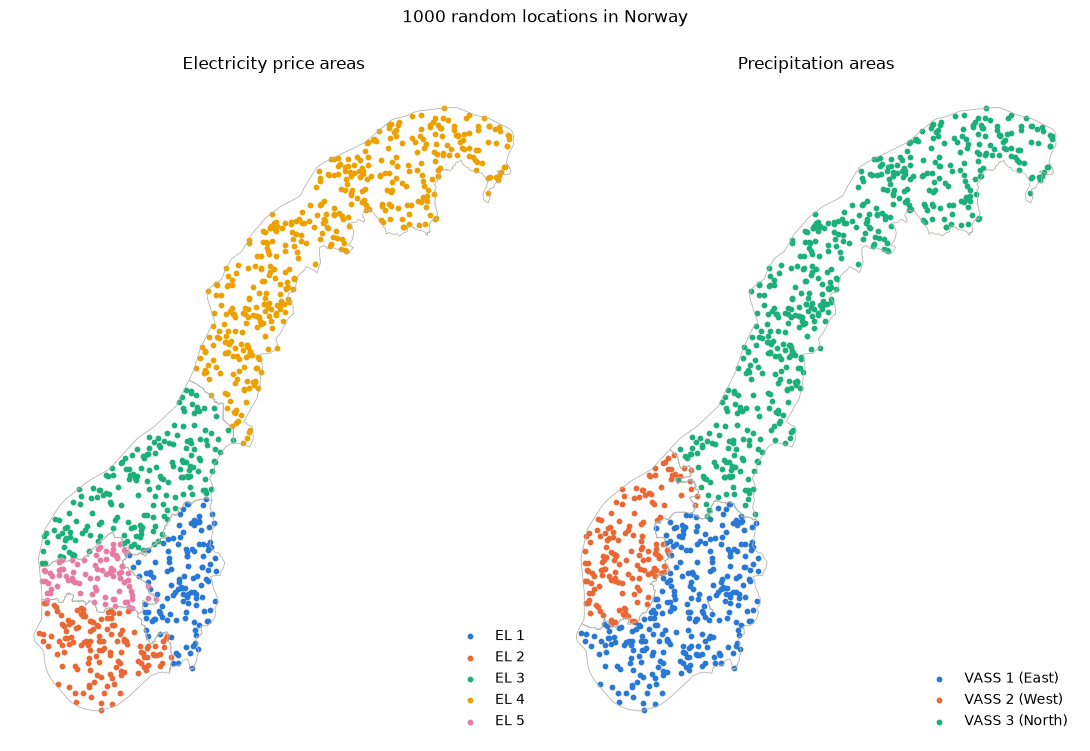

In [6]:
# Map of the sampled locations, once per area type
EL_COLORS = dict(zip(sorted(price_areas["el_area"]), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
VASS_COLORS = dict(zip(sorted(set(REGION_TO_VASS.values())), ["#2a78d6", "#eb6834", "#1baf7a"]))
VASS_LABELS = {"VASS 1": "VASS 1 (East)", "VASS 2": "VASS 2 (West)", "VASS 3": "VASS 3 (North)"}

fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharex=True, sharey=True)

for ax, areas, column, colors, title in [
    (axes[0], price_areas, "el_area", EL_COLORS, "Electricity price areas"),
    (axes[1], nve_regions.dissolve("vass_area").reset_index(), "vass_area", VASS_COLORS, "Precipitation areas"),
]:
    areas.boundary.plot(ax=ax, color="#b5b4ad", linewidth=0.6)
    for area, group in samples.groupby(column):
        group.plot(ax=ax, color=colors[area], markersize=10, label=VASS_LABELS.get(area, area))
    ax.set_title(title)
    ax.set_axis_off()
    ax.legend(loc="lower right", frameon=False)

fig.suptitle(f"{N_POINTS} random locations in Norway")
plt.tight_layout()
plt.show()


## Weather data from Open-Meteo (ERA5)

The weather data comes from Open-Meteo's historical API, using the ERA5 reanalysis model (`models=era5`, about 25 km resolution). `download_weather` takes a region (`EL 1`–`EL 5` or `VASS 1`–`VASS 3`) and a time interval, finds the sampled locations in that region, and downloads daily values for each one.

**API limits:** the free tier allows 10,000 calls per day, 5,000 per hour and 600 per minute, but a request can count as more than one call. The `X-RateLimit-Cost` response header shows the real cost, which I measured:

| Request (one location) | Cost in calls |
|---|---|
| 14 days, 10 variables | 1.00 |
| 1 year, 10 variables | 26.07 |
| 1 year, 5 variables | 13.04 |
| 1 year, 12 variables | 31.29 |

So the cost is about `days / 14 × variables / 10` per location, with a minimum of 1 call. One year for all 1000 locations costs about 26,000 calls, which is more than one day allows. To stay inside the limits the function:

- saves each location and year to `No_sync/era5/`, so nothing is downloaded twice, even though each location belongs to both an `EL` and a `VASS` area
- counts the calls used today and stops at `DAILY_BUDGET`; running it again the next day continues where it stopped
- waits between requests to stay under the hourly limit
- tries again after a timeout, and stops if the API answers 429 (limit reached)
- with `dry_run=True`, only prints what a download would cost

ERA5 data arrives about 5 days late, so the end date is moved back if it is too recent. Otherwise, empty days would be saved in the cache.

Locations in the same ERA5 grid cell are still downloaded separately: Open-Meteo adjusts the temperature to each location's own elevation, so the temperature and the split between rain and snow differ even inside one cell.


In [ ]:
import hashlib
import json
import time
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

ERA5_URL = "https://archive-api.open-meteo.com/v1/archive"

# Exactly 10 variables: each extra one adds 10% to the cost of every request
DAILY_VARIABLES = [
    "precipitation_sum",           # mm, rain and snow together
    "rain_sum",                    # mm
    "snowfall_sum",                # cm, snow stored until it melts
    "precipitation_hours",         # hours with precipitation
    "temperature_2m_mean",         # °C
    "temperature_2m_max",          # °C
    "temperature_2m_min",          # °C
    "wind_speed_10m_mean",         # m/s
    "shortwave_radiation_sum",     # MJ/m², drives snowmelt
    "et0_fao_evapotranspiration",  # mm, water lost to the air
]

DAILY_BUDGET = 9000     # stay under the limit of 10,000, in case other things use the API
HOURLY_LIMIT = 5000
ERA5_DELAY_DAYS = 7     # 5 days according to the docs, with some margin

CACHE_DIR = Path("../No_sync/era5")   # gitignored
USAGE_FILE = CACHE_DIR / "usage.json"


In [ ]:
def calls_used_today():
    """Calls counted so far today. The day follows UTC."""
    today = str(datetime.now(timezone.utc).date())
    if not USAGE_FILE.exists():
        return 0.0
    return json.loads(USAGE_FILE.read_text()).get(today, 0.0)

def add_calls(cost):
    """Add the cost of a request to today's total."""
    today = str(datetime.now(timezone.utc).date())
    usage = json.loads(USAGE_FILE.read_text()) if USAGE_FILE.exists() else {}
    usage[today] = usage.get(today, 0.0) + cost
    USAGE_FILE.write_text(json.dumps(usage))

def locations_in_region(region):
    """Look up the sampled locations for a region, e.g. "EL 1" or "VASS 3"."""
    column = "el_area" if region.startswith("EL") else "vass_area"
    points = samples.loc[samples[column] == region, ["lon", "lat", "el_area", "vass_area"]]
    if points.empty:
        raise ValueError(f"Unknown region: {region}")
    return points

def split_by_year(start, end):
    """Split an interval into one (start, end) pair per calendar year."""
    return [
        (max(start, date(year, 1, 1)), min(end, date(year, 12, 31)))
        for year in range(start.year, end.year + 1)
    ]

def estimate_cost(chunk_start, chunk_end, n_variables):
    """Cost in API calls of one request for one location."""
    days = (chunk_end - chunk_start).days + 1
    return max(days / 14 * n_variables / 10, 1)

def cache_path(lon, lat, chunk_start, chunk_end, variables):
    """File for one location and year. The hash keeps different variable lists apart."""
    variables_id = hashlib.md5(",".join(variables).encode()).hexdigest()[:8]
    return CACHE_DIR / variables_id / f"{lat:.4f}_{lon:.4f}_{chunk_start}_{chunk_end}.parquet"

def fetch_location(lon, lat, chunk_start, chunk_end, variables):
    """Download one location and year. Returns the data and the real cost in calls."""
    resp = requests.get(ERA5_URL, timeout=20, params={   # a normal answer takes under a second
        "latitude": lat,
        "longitude": lon,
        "start_date": chunk_start,
        "end_date": chunk_end,
        "daily": ",".join(variables),
        "models": "era5",
        "timezone": "Europe/Oslo",   # days match the Norwegian calendar, as in part 2
        "wind_speed_unit": "ms",
    })
    resp.raise_for_status()
    result = resp.json()
    data = pd.DataFrame(result["daily"]).rename(columns={"time": "date"})
    data["date"] = pd.to_datetime(data["date"])
    # the ERA5 grid cell that was actually used, which is often not at the exact location
    data["grid_lat"] = result["latitude"]
    data["grid_lon"] = result["longitude"]
    data["elevation"] = result["elevation"]
    return data, float(resp.headers["X-RateLimit-Cost"])


In [ ]:
def fetch_with_retries(lon, lat, chunk_start, chunk_end, variables, attempts=3):
    """Try again after timeouts and connection errors, which are usually short."""
    for attempt in range(1, attempts + 1):
        try:
            return fetch_location(lon, lat, chunk_start, chunk_end, variables)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == attempts:
                raise
            print(f"  no answer from the API, trying again (attempt {attempt} of {attempts})")
            time.sleep(10)

def download_weather(region, start, end, variables=DAILY_VARIABLES, dry_run=False):
    """Daily ERA5 weather for all sampled locations in a region.

    region: "EL 1"-"EL 5" or "VASS 1"-"VASS 3"
    start, end: dates as text, e.g. "2024-01-01" (both included)
    dry_run: only print what the download would cost

    Returns what is available so far. If the daily budget runs out, the same
    call continues from where it stopped the next day.
    """
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    start = date.fromisoformat(start)
    end = date.fromisoformat(end)

    latest = date.today() - timedelta(days=ERA5_DELAY_DAYS)
    if end > latest:
        print(f"ERA5 is not available that late, using {latest} as the end date")
        end = latest

    points = locations_in_region(region)
    chunks = split_by_year(start, end)

    # one job per location and year; the ones already saved are skipped
    jobs = [
        (point_id, point.lon, point.lat, chunk_start, chunk_end)
        for point_id, point in points.iterrows()
        for chunk_start, chunk_end in chunks
    ]
    paths = {job: cache_path(job[1], job[2], job[3], job[4], variables) for job in jobs}
    todo = [job for job in jobs if not paths[job].exists()]

    cost = sum(estimate_cost(job[3], job[4], len(variables)) for job in todo)
    used = calls_used_today()
    print(f"{region}: {len(points)} locations, {len(jobs) - len(todo)} of {len(jobs)} requests already saved")
    print(f"Cost of the rest: {cost:.0f} calls. Used today: {used:.0f} of {DAILY_BUDGET}.")
    if dry_run:
        return None

    done = 0
    for job in todo:
        point_id, lon, lat, chunk_start, chunk_end = job
        estimate = estimate_cost(chunk_start, chunk_end, len(variables))
        if calls_used_today() + estimate > DAILY_BUDGET:
            print(f"Daily budget reached after {done} of {len(todo)} requests. Run it again tomorrow.")
            break
        try:
            data, real_cost = fetch_with_retries(lon, lat, chunk_start, chunk_end, variables)
        except requests.HTTPError as error:
            if error.response.status_code == 429:
                print(f"API limit reached after {done} of {len(todo)} requests: {error.response.text}")
                break
            raise
        except (requests.Timeout, requests.ConnectionError):
            print(f"The API is not answering, stopped after {done} of {len(todo)} requests. Run it again later.")
            break

        paths[job].parent.mkdir(exist_ok=True)
        data.to_parquet(paths[job])
        add_calls(real_cost)
        done += 1
        if done % 25 == 0:
            print(f"  {done} of {len(todo)} requests done")
        time.sleep(real_cost * 3600 / HOURLY_LIMIT)   # stays under the hourly and minute limits

    saved = [
        pd.read_parquet(paths[job]).assign(point_id=job[0], region=region)
        for job in jobs if paths[job].exists()
    ]
    if len(saved) < len(jobs):
        print(f"Note: {len(jobs) - len(saved)} of {len(jobs)} requests are still missing from this result")
    return pd.concat(saved, ignore_index=True) if saved else pd.DataFrame()


In [ ]:
# what would one year cost for each region?
for region in ["EL 1", "EL 2", "EL 3", "EL 4", "EL 5", "VASS 1", "VASS 2", "VASS 3"]:
    download_weather(region, "2024-01-01", "2024-12-31", dry_run=True)


In [ ]:
# small test: two weeks for the smallest region (about 86 calls the first time, 0 after that)
weather = download_weather("EL 5", "2025-01-01", "2025-01-14")
print(weather.shape)
print(f"Used today: {calls_used_today():.0f} calls")
weather.head()


In [ ]:
# each location should have one row per day, and no missing values
print(weather.groupby("point_id").size().value_counts())
print(f"Missing values: {weather.isna().sum().sum()}")

# several locations can share an ERA5 grid cell, since the grid is about 25 km
n_cells = weather[["grid_lat", "grid_lon"]].drop_duplicates().shape[0]
print(f"{weather['point_id'].nunique()} locations use {n_cells} ERA5 grid cells")

weather[["precipitation_sum", "temperature_2m_mean", "snowfall_sum", "wind_speed_10m_mean"]].describe().round(2)


## Log


i started we downloading the shapefilse from NVE atalts. thise represented the electricity areas and precipitation areas that correspond to the Magasinstatistikk data used earlier in the project. since we only have vass 1, 2, and 3 i needed to combine some of the regions. Then i verefyed thet the areas mach up withe the power capacity for whole norway.

## AI usage
